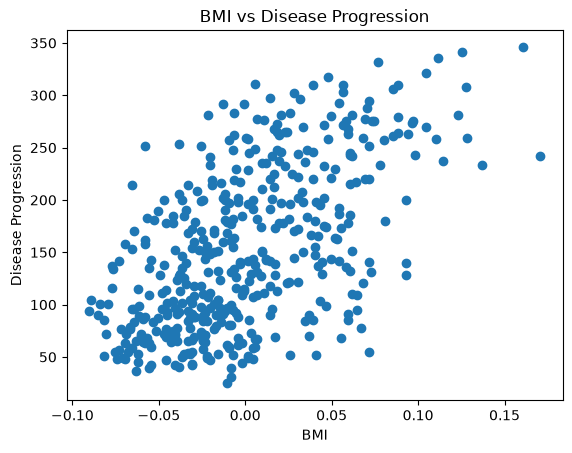

Correlation: 0.5864501344746884


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

diabetes = load_diabetes()

df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df["target"] = diabetes.target

X = df[["bmi"]]
y = df["target"]

plt.scatter(X, y)
plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("BMI vs Disease Progression")
plt.show()

correlation = df["bmi"].corr(df["target"])
print("Correlation:", correlation)

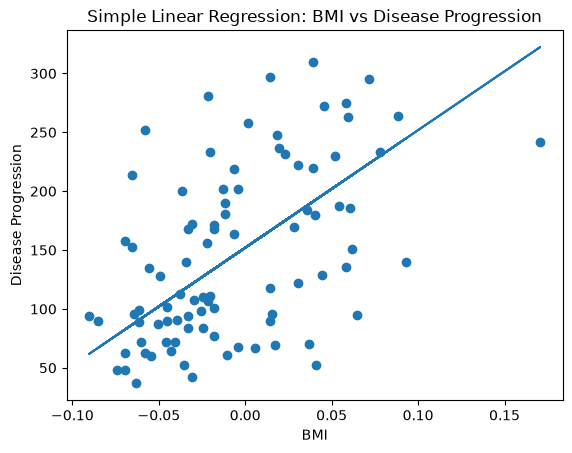

Mean Squared Error: 4061.8259284949268
R² Score: 0.23335039815872138


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred)
plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Simple Linear Regression: BMI vs Disease Progression")
plt.show()

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R² Score:", r2)

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


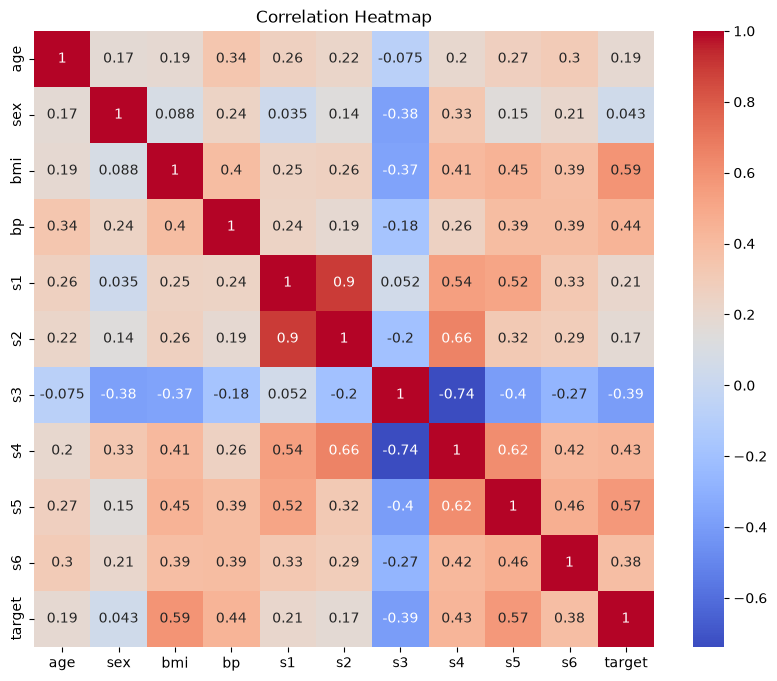

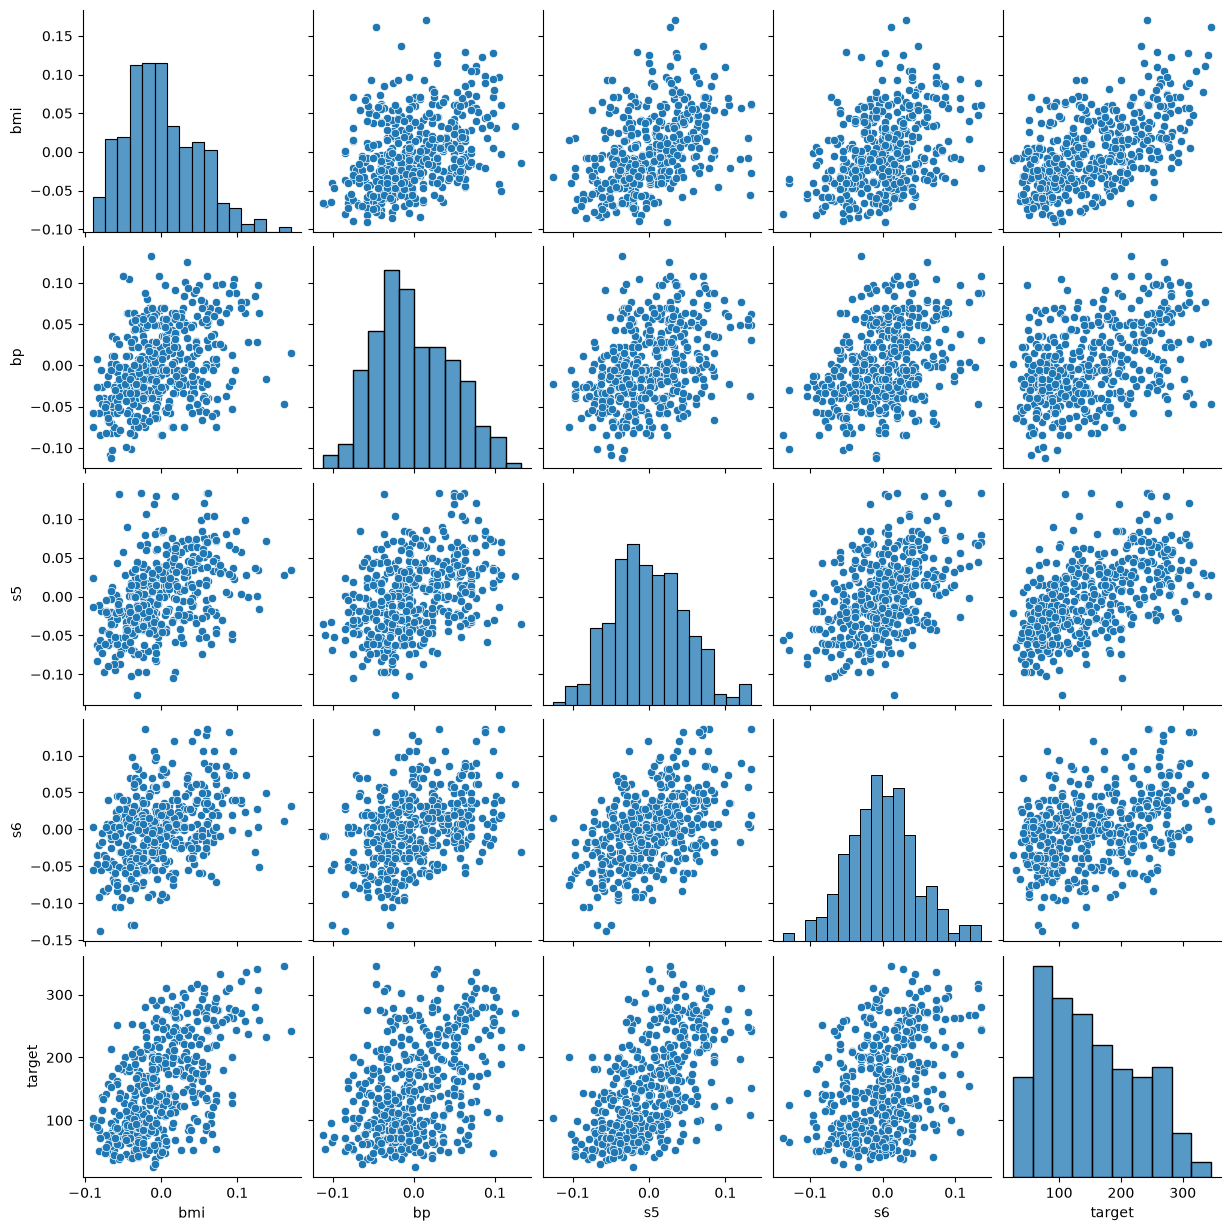

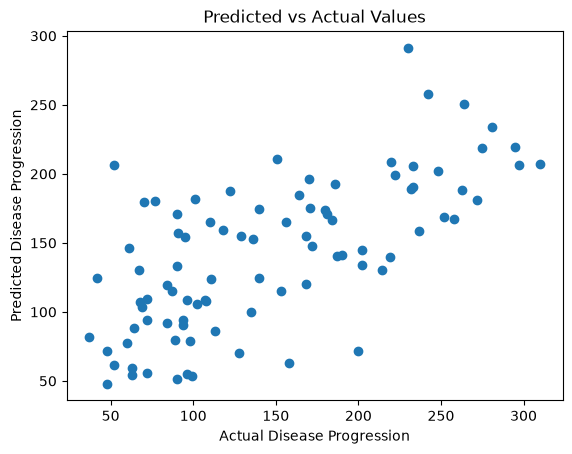

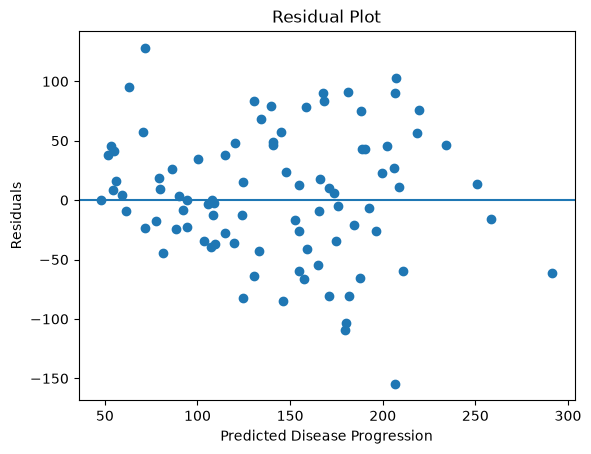

Multivariate Linear Regression
MSE: 2900.1936284934814
RMSE: 53.85344583676593
R² Score: 0.4526027629719195

Feature Coefficients:
  Feature  Coefficient
4      s1  -931.488846
8      s5   736.198859
2     bmi   542.428759
5      s2   518.062277
3      bp   347.703844
7      s4   275.317902
1     sex  -241.964362
6      s3   163.419983
9      s6    48.670657
0     age    37.904021


In [8]:
diabetes = load_diabetes()

df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df["target"] = diabetes.target

print(df.head())

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

selected_features = ["bmi", "bp", "s5", "s6", "target"]

sns.pairplot(df[selected_features])
plt.show()

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train, y_train)

y_pred_multi = model_multi.predict(X_test)

plt.scatter(y_test, y_pred_multi)
plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Predicted vs Actual Values")
plt.show()

residuals = y_test - y_pred_multi

plt.scatter(y_pred_multi, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Disease Progression")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

mse_multi = mean_squared_error(y_test, y_pred_multi)
rmse_multi = np.sqrt(mse_multi)
r2_multi = r2_score(y_test, y_pred_multi)

print("Multivariate Linear Regression")
print("MSE:", mse_multi)
print("RMSE:", rmse_multi)
print("R² Score:", r2_multi)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model_multi.coef_
})

print("\nFeature Coefficients:")
print(coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
))

In [9]:

comparison = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multivariate Linear Regression"
    ],
    "MSE": [
        mse,
        mse_multi
    ],
    "RMSE": [
        np.sqrt(mse),
        rmse_multi
    ],
    "R²": [
        r2,
        r2_multi
    ]
})

print(comparison)

                            Model          MSE       RMSE        R²
0        Simple Linear Regression  4061.825928  63.732456  0.233350
1  Multivariate Linear Regression  2900.193628  53.853446  0.452603
